## 1. Import Libraries

Load all the libraries we need:

- **`numpy`, `pandas`** — for data processing
- **`matplotlib`, `seaborn`** — for charts
- **`scikit-learn`** — for data splitting, imputing, encoding, pipelines, and regression models
- **`xgboost`** — for the `XGBRegressor` model
- **`category_encoders`** — another option for encoding categories

In [90]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.impute import SimpleImputer
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from sklearn.model_selection import KFold, cross_val_score
import category_encoders as ce
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline as SklearnPipeline

## 2. Load the Dataset

Read `County_Health_Rankings.csv` into a DataFrame called `ch`.

In [91]:
ch = pd.read_csv("D:/belajar/dataset/County_Health_Rankings.csv")

## 3. Summary Statistics

Show a quick summary of the numeric columns with `describe()`: the spread of values, the min and max, and how many rows are not empty.

We can already see that some columns have many missing values (for example `Denominator`, `Confidence Interval`, and `Data Release Year`), because each row only has data for one type of measure.

In [92]:
ch.describe()

,State code,County code,Measure id,Numerator,Denominator,Raw value,Confidence Interval Lower Bound,Confidence Interval Upper Bound,Data Release Year,fipscode
count,303860.000000,303860.000000,303390.000000,2.140760e+05,1.847790e+05,289956.000000,189412.000000,189412.000000,150129.000000,294283.000000
mean,30.351807,101.981422,38.699071,1.253031e+04,1.354018e+05,1075.912013,1348.410687,1851.042897,2012.256280,30456.873139
std,15.238258,107.824989,36.791425,3.516778e+05,3.666322e+06,2851.499091,2902.214152,3998.423557,1.312575,15258.982388
min,0.000000,0.000000,1.000000,0.000000e+00,1.000000e+01,0.000000,0.000000,0.000000,2010.000000,0.000000
25%,18.000000,33.000000,7.000000,2.180000e+02,2.127000e+03,0.200000,0.183425,0.277939,2011.000000,18179.000000
50%,29.000000,77.000000,24.000000,8.190000e+02,8.446023e+03,0.585000,0.278000,0.400000,2012.000000,29183.000000
75%,45.000000,133.000000,50.000000,2.686000e+03,2.822000e+04,91.082228,62.000000,77.000000,2013.000000,45087.000000
max,72.000000,840.000000,125.000000,6.214471e+07,6.026833e+08,32810.400000,23917.100000,46148.300000,2014.000000,72153.000000


## 4. Correlation Between Numeric Features

Calculate the correlation matrix of all numeric columns and draw it as a heatmap. This helps us see which columns move together, for example the confidence interval columns and `Raw value`.

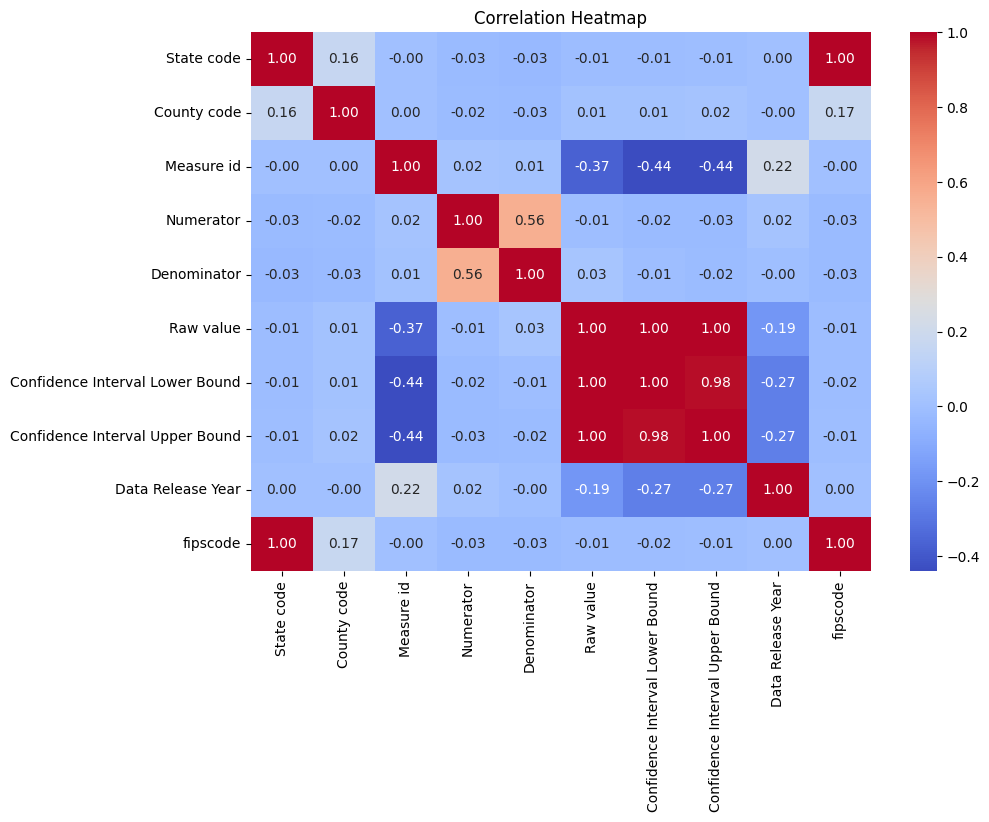

In [93]:
numeric_data = ch.select_dtypes(include='number')
corr_matrix = numeric_data.corr()   

# Visualisasi
plt.figure(figsize=(10, 7))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')
plt.show()

## 5. Select "Adult Obesity" Data and Set Features/Target

- Keep only the rows where the measure is `Adult obesity`
- **Target (`y`)** = `Raw value` (the adult obesity percentage)
- **Features (`X`)** = all other columns except `Raw value` and columns that would leak the answer (`Measure name`, `Measure id`, `Numerator`, `Denominator`, and the confidence interval bounds)

The remaining feature columns are: `State`, `County`, `State code`, `County code`, `Year span`, `Data Release Year`, `fipscode`.

In [94]:
# Filter indikator Adult Obesity
ch_obesity = ch[ch['Measure name'] == 'Adult obesity'].copy()

# Menentukan fitur dan target
X = ch_obesity.drop(columns=[
    'Raw value',
    'Measure name',
    'Measure id',
    'Confidence Interval Lower Bound',
    'Confidence Interval Upper Bound',
    'Numerator', 'Denominator'
])

y = ch_obesity['Raw value']

X.columns

Index(['State', 'County', 'State code', 'County code', 'Year span',
       'Data Release Year', 'fipscode'],
      dtype='object')

## 6. Convert `Year span` to Numeric

Turn `Year span` into a number with `errors='coerce'`. Any value that cannot be converted becomes `NaN`, and the imputer will handle it later.

In [95]:
X['Year span'] = pd.to_numeric(
    X['Year span'], errors='coerce'
)

## 7. Preview the Features (`X`)

Show the first 5 rows of `X`. You can see the national summary rows (`State = US`, `County = United States`), where `Data Release Year` is empty (`NaN`).

In [96]:
X.head()

,State,County,State code,County code,Year span,Data Release Year,fipscode
214394,US,United States,0.0,0.0,2004,NaN,0.0
214395,US,United States,0.0,0.0,2005,NaN,0.0
214396,US,United States,0.0,0.0,2006,NaN,0.0
214397,US,United States,0.0,0.0,2007,NaN,0.0
214398,US,United States,0.0,0.0,2008,2011.0,0.0


## 8. Identify Numeric Columns

List the numeric columns in `X`: `State code`, `County code`, `Year span`, `Data Release Year`, and `fipscode`. We use this list to decide which columns go into the numeric pipeline.

In [97]:
numeric_cols = X.select_dtypes(include=[np.number]).columns.tolist()
print(numeric_cols)

['State code', 'County code', 'Year span', 'Data Release Year', 'fipscode']


## 9. Correlation Between Numeric Features in `X`

Draw a heatmap for the numeric features in `X`. `State code`, `County code`, and `fipscode` are strongly correlated because all three describe the same thing: where the county is located.

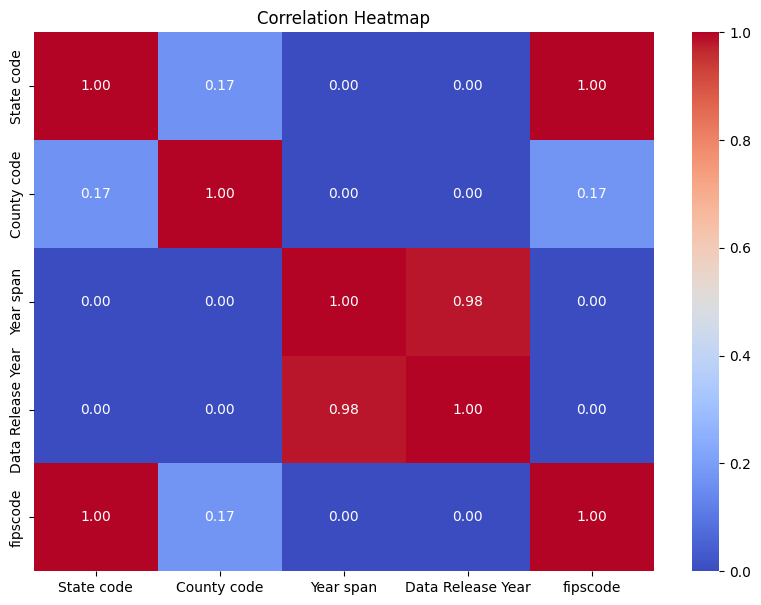

In [98]:
numeric_data = X.select_dtypes(include='number')
corr_matrix = numeric_data.corr()   

# Visualisasi
plt.figure(figsize=(10, 7))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')
plt.show()

## 10. Check the `Raw value`

Test the idea that `Raw value` = `Numerator / Denominator × 100` and look at the difference.

The difference is large and always about 1000 times bigger, so `Raw value` is stored in a different scale than a plain percentage. This matters when we read the model's predictions.

In [99]:
# Menghitung nilai berdasarkan dugaan rumus
calculated_value = (
    ch['Numerator'] / ch['Denominator'] * 100
)

# Membandingkan dengan Raw value
comparison = pd.DataFrame({
    'Raw value': ch['Raw value'],
    'Calculated value': calculated_value
})

comparison['Difference'] = (
    comparison['Raw value'] -
    comparison['Calculated value']
)

print(comparison.head(10))

    Raw value  Calculated value  Difference
0  483.398066          0.483398  482.914668
1  483.021233          0.483021  482.538212
2  483.529230          0.483529  483.045701
3  475.263942          0.475264  474.788678
4  457.808585          0.457809  457.350777
5  433.499335          0.433499  433.065835
6  409.362388          0.409362  408.953026
7  430.555907          0.430556  430.125351
8  437.326488          0.437326  436.889161
9  438.745515          0.438746  438.306770


## 11. Split Data into Train and Test

Split the data into **80% for training** and **20% for testing** using `train_test_split`, with `random_state=42` so the result is always the same.

In [100]:
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size= 0.8, random_state= 42)

## 12. Check Missing Values in Training Data

Find the columns in `X_train` that still have empty values and show their data types. Only `Data Release Year` (float64) has `NaN`, and the imputer in the pipeline will fill it.

In [101]:
kolom_null =X_train.columns[X_train.isnull().any()]

tipe_data = X_train[kolom_null].dtypes

print(tipe_data)

Data Release Year    float64
dtype: object


## 13. Check Missing Values in Test Data

Do the same check for `X_test`. The result is the same: only `Data Release Year` has empty values, so the same imputing strategy works.

In [102]:
kolom_null_test = X_test.columns[X_test.isnull().any()]

tipe_data = X_test[kolom_null_test].dtypes

print(tipe_data)

Data Release Year    float64
dtype: object


## 14. Preview the Features Again

Show the first 5 rows of `X` one more time as a final check before the data goes into the preprocessing pipeline.

In [103]:
X.head()

,State,County,State code,County code,Year span,Data Release Year,fipscode
214394,US,United States,0.0,0.0,2004,NaN,0.0
214395,US,United States,0.0,0.0,2005,NaN,0.0
214396,US,United States,0.0,0.0,2006,NaN,0.0
214397,US,United States,0.0,0.0,2007,NaN,0.0
214398,US,United States,0.0,0.0,2008,2011.0,0.0


## 15. Build the Preprocessor

Create a `ColumnTransformer` with two pipelines:

- **Numeric** (`State code`, `County code`, `Data Release Year`, `fipscode`, `Year span`) → fill empty values with the **median**
- **Categorical** (`State`, `County`) → fill empty values with the **most frequent value**, then apply **One-Hot Encoding** (`handle_unknown='ignore'` so new categories never cause an error)

Any other column is dropped (`remainder='drop'`).

In [104]:
X_train_final = X_train.copy()
X_test_final = X_test.copy()

numerical_cols = ['State code', 'County code', 'Data Release Year', 'fipscode', 'Year span']
categorical_cols = ['State', 'County']

# Pipeline numerik
numeric_pipeline = SklearnPipeline(steps=[
    ('imputer', SimpleImputer(strategy='median'))
])


categorical_pipeline = SklearnPipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('numeric', numeric_pipeline,numeric_cols),
        ('categorical', categorical_pipeline, categorical_cols)
    ],
    remainder='drop'
)

print("Preprocessor siap")


Preprocessor siap


## 16. Compare Baseline Models

Train and test three regression models with the same preprocessing pipeline:

1. **RandomForestRegressor**
2. **LinearRegression**
3. **XGBoost**

We score each model on the test data with **MAE** (Mean Absolute Error). Random Forest has the lowest MAE (about 0.0143), followed by XGBoost and Linear Regression.

In [106]:
model = {
    'RandomForestRegressor' : RandomForestRegressor(random_state=42, n_estimators=100),
    'LinearRegression': LinearRegression(),
    'XGBoost': XGBRegressor(random_state=42, n_estimators=100)
}

results = []

for name, models in model.items():
    my_pipeline = SklearnPipeline([
        ('preprocessor', preprocessor),
        ('model', models)
    ])

    my_pipeline.fit(X_train_final, y_train)

    y_pred = my_pipeline.predict(X_test_final)

    Eval = mean_absolute_error(y_test, y_pred)

    results.append({
        'Model': name,
        'MAE': Eval,
    })

results_df = pd.DataFrame(results)
print(results_df)

                   Model       MAE
0  RandomForestRegressor  0.014297
1       LinearRegression  0.018005
2                XGBoost  0.015695


## 17. Evaluate the Best Model

Train **RandomForestRegressor** again with tuned settings (`n_estimators=200`, `max_depth=10`, `min_samples_leaf=5`) and score it on both the training and test data.

The MAE on train (about 0.0208) and on test (about 0.0208) are almost the same, so the model is **not overfitting** and works well on new data.

In [107]:
best_model = RandomForestRegressor(random_state=42, n_estimators=200, max_depth=10, min_samples_leaf=5)

new_pipeline = SklearnPipeline([
    ('preprocessor', preprocessor),
    ('RandomForestRegressor', best_model)
])

new_pipeline.fit(X_train_final, y_train)
y_preds_train= new_pipeline.predict(X_train_final)
y_preds_test = new_pipeline.predict(X_test_final)

eval_train = mean_absolute_error(y_train, y_preds_train)
eval_test = mean_absolute_error(y_test, y_preds_test)

print("Evaluation model using training data", eval_train)
print("Evaluation model using testing data", eval_test)

Evaluation model using training data 0.02080776953779163
Evaluation model using testing data 0.020788840309535442


## 18. Predict and Save the Results

Build a table that compares the **actual value vs the prediction**, plus the **absolute error**, for the first 10 rows. Then save all predictions to `hasil_prediksi_adult_obesity.csv`.

In [108]:
prediction_df = pd.DataFrame({
    'Measure_name': ch_obesity.loc[X_test.index, 'Measure name'].values,
    'Actual': y_test.values,
    'Prediction': y_preds_test
}, index=X_test.index)

prediction_df['Absolute_Error'] = (
    prediction_df['Actual'] - prediction_df['Prediction']
).abs()

display(prediction_df.head(10))

prediction_df.to_csv('hasil_prediksi_adult_obesity.csv', index=False)
print("File hasil_prediksi_adult_obesity.csv berhasil disimpan.")


,Measure_name,Actual,Prediction,Absolute_Error
223097,Adult obesity,0.220,0.260119,0.040119
220532,Adult obesity,0.322,0.305612,0.016388
228397,Adult obesity,0.360,0.289050,0.070950
218934,Adult obesity,0.280,0.289142,0.009142
227306,Adult obesity,0.200,0.253906,0.053906
234542,Adult obesity,0.310,0.268893,0.041107
228641,Adult obesity,0.270,0.269893,0.000107
229281,Adult obesity,0.310,0.306627,0.003373
214641,Adult obesity,0.340,0.330229,0.009771
231150,Adult obesity,0.400,0.317864,0.082136


File hasil_prediksi_adult_obesity.csv berhasil disimpan.
